# Parallel TEM illumination

Design an operating condition using the **same geometry and source as the working ray calibration**. This notebook does not change that calibration acquisition or refit the microscope.

The condenser mini images an upstream source crossover onto the **front focal plane of the objective pre-field**. The pre-field then collimates the beam. This is the TEM illumination condition described by [JEOL](https://www.jeol.com/words/emterms/20121023.024259.php).

The first example keeps mini at **1.5 relative current** and objective current fixed. The detector-ready example in section 4 retunes mini to **2.45** for **20/50 µm apertures**. Solve CL1 and CL3 together to change source-image size while preserving this condition. These controls belong to the synthetic model; they are not NEOARM DAC values.

In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import json
from pathlib import Path
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from temgym_core import calibration
from temgym_core.calibration.apertures import (
    aperture_centres, effective_parameters, make_aperture_moments,
)
from temgym_core.calibration.condenser_model import (
    condenser_components, condenser_with_aperture, first_crossover_fraction,
    source_moments,
)
from temgym_core.run import column_matrix

reference = Path("calibration_results/crossover_ray_acquisition")
experiment = json.loads((reference / "experiment.json").read_text())
truth = json.loads((reference / "scoring_truth.json").read_text())
print("JAX devices:", jax.devices())

JAX devices: [CudaDevice(id=0)]


**1. Design the curve.** Supply the existing physical parameters, desired source-image magnifications and one fixed mini setting. The output is a source-image plane and rows of `[CL1, CL3, mini]` controls.

The existing function first finds the front focal plane of **mini plus pre-field**. It then makes CL1/CL3 image the source onto that plane. Equivalently, mini relays that image to the pre-field's own front focal plane.

For the full source-to-specimen matrix,
$$
\boldsymbol{\theta}_S=C\mathbf{x}_0+D\boldsymbol{\theta}_0.
$$
The point-source collimation condition is $D=0$. Finite source size still gives angular spread through $C$. This is not an image of the source at the specimen.

In [2]:
source_image_magnifications = [0.10, 0.20, 0.30, 0.50]
mini_control = 1.5
parameters_by_voltage = []
curves = []

for voltage_index, voltage in enumerate(experiment["voltages_v"]):
    parameters = effective_parameters(
        jnp.array(truth["condenser_parameters"]),
        voltage, experiment["voltages_v"][0], voltage_index,
    )
    curve = calibration.design_condenser_curve(
        parameters,
        image_magnifications=source_image_magnifications,
        mini_control=mini_control,
    )
    parameters_by_voltage.append(parameters)
    curves.append(curve)
    print(f"{voltage / 1000:.0f} kV: source-image plane {curve['image_plane_z_m'] * 1000:.3f} mm")

print("Source image m     CL1       CL3      Mini")
for magnification, controls in zip(source_image_magnifications, curves[0]["controls"]):
    print(f"{magnification:14.2f}  {controls[0]:8.4f}  {controls[1]:8.4f}  {controls[2]:8.4f}")

200 kV: source-image plane -40.630 mm


195 kV: source-image plane -39.856 mm
Source image m     CL1       CL3      Mini
          0.10    3.3928    1.5016    1.5000
          0.20    2.7521    1.6479    1.5000
          0.30    2.5113    1.7848    1.5000
          0.50    2.3036    2.0389    1.5000


**2. Check the illumination with each aperture inserted.** Predict the transmitted beam's position and angular covariance using native components and aperture transmission.

The width below is **four times the per-axis RMS width**, not a hard-edged diameter. Angles are per-axis RMS values, not convergence semi-angles. These are geometric-ray predictions; aperture diffraction is disabled to match the current ray model.

In [3]:
measurements = []
for voltage_index, voltage in enumerate(experiment["voltages_v"]):
    parameters = parameters_by_voltage[voltage_index]
    curve = curves[voltage_index]
    source_z = -jnp.exp(parameters[:9]).sum()
    for aperture_index, diameter in enumerate(experiment["aperture_diameters_um"]):
        predict = make_aperture_moments(
            radius_m=diameter * 0.5e-6,
            edge_width_m=experiment["aperture_edge_width_m"],
            voltage_v=voltage,
            diffraction=False,
        )
        for magnification, controls in zip(source_image_magnifications, curve["controls"]):
            mean, covariance, transmission = predict(
                parameters, controls, aperture_centres(parameters, 2)[aperture_index] * 1e-6,
            )
            matrix = np.asarray(column_matrix(
                condenser_components(parameters, controls), source_z=source_z, voltage=voltage,
            ))
            measurements.append({
                "kV": voltage / 1000,
                "Aperture (µm)": diameter,
                "Source image m": magnification,
                "Beam width, 4σ (µm)": 4 * np.sqrt(np.trace(covariance[:2, :2]) / 2) * 1e6,
                "Angular σ (µrad)": np.sqrt(np.trace(covariance[2:, 2:]) / 2) * 1e6,
                "Transmission": float(transmission),
                "Crossover fraction": float(first_crossover_fraction(parameters, controls)),
                "D norm": np.linalg.norm(matrix[2:4, 2:4]),
            })

assert max(row["D norm"] for row in measurements) < 1e-6
assert all(0.01 < row["Crossover fraction"] < 0.99 for row in measurements)
print(" kV   Aperture µm   Image m   Width 4σ µm   Angle σ µrad   Transmitted")
for row in measurements:
    print(f"{row['kV']:3.0f} {row['Aperture (µm)']:12.0f} {row['Source image m']:9.2f} "
          f"{row['Beam width, 4σ (µm)']:13.3f} {row['Angular σ (µrad)']:14.3f} "
          f"{row['Transmission']:13.1%}")

 kV   Aperture µm   Image m   Width 4σ µm   Angle σ µrad   Transmitted
200           50      0.10         2.105          0.468         24.7%
200           50      0.20         1.946          0.937         67.8%
200           50      0.30         1.690          1.405         92.2%
200           50      0.50         1.142          2.342         99.9%
200          150      0.10         5.081          0.468         92.4%
200          150      0.20         2.862          0.937        100.0%
200          150      0.30         1.909          1.405        100.0%
200          150      0.50         1.145          2.342        100.0%
195           50      0.10         1.905          0.523         24.7%
195           50      0.20         1.761          1.046         67.8%
195           50      0.30         1.529          1.568         92.2%
195           50      0.50         1.033          2.614         99.9%
195          150      0.10         4.597          0.523         92.4%
195          150   

**3. Inspect the rays.** The following diagram uses native ray tracing, with the 50 µm aperture inserted. It shows three sections of the same 200 kV setting at source-image magnification 0.20. The envelope illustrates a two-RMS source bundle and clips rays at the aperture radius; the table above uses its smooth transmission.

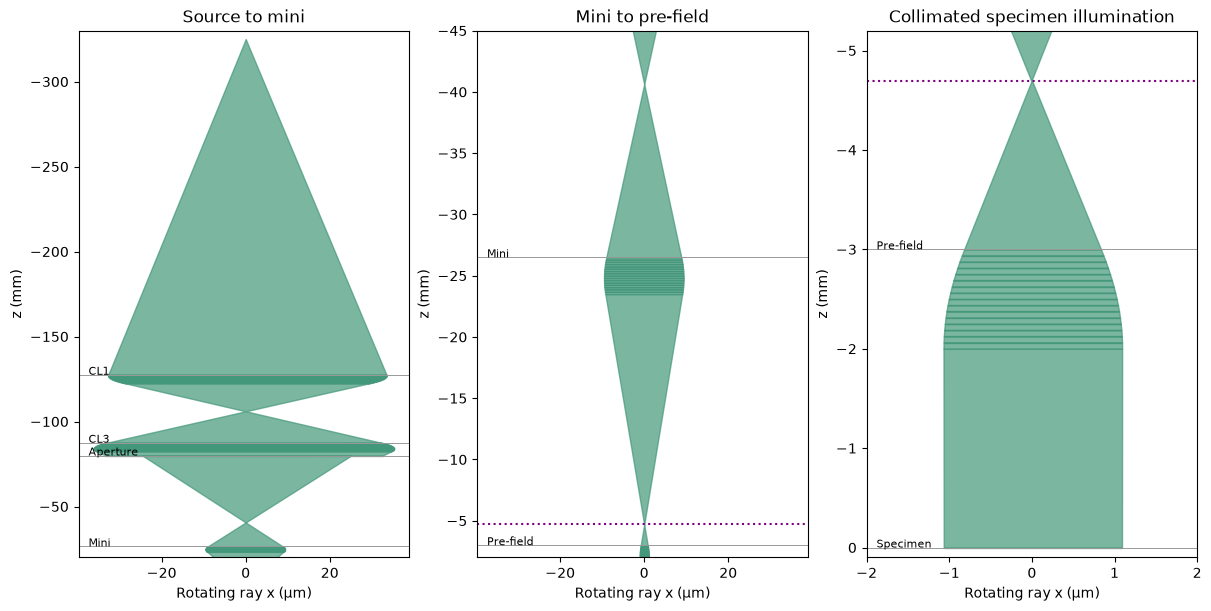

Pre-field front focal plane: -4.696 mm


In [4]:
from temgym_core.components import Plane
from temgym_core.plotting import trace_ray_envelope
from temgym_core.ray import Ray

parameters = parameters_by_voltage[0]
controls = curves[0]["controls"][1]
mean, covariance = map(np.asarray, source_moments(parameters))
phase = np.linspace(0, 2 * np.pi, 512, endpoint=False)
rays = Ray(
    x=mean[0] + 2 * np.sqrt(covariance[0, 0]) * np.cos(phase),
    y=np.full(512, mean[1]),
    dx=mean[2] + 2 * np.sqrt(covariance[2, 2]) * np.sin(phase),
    dy=np.full(512, mean[3]),
    z=-float(jnp.exp(parameters[:9]).sum()), pathlength=0., voltage=200000.,
)
column = condenser_with_aperture(
    parameters, controls, radius_m=25e-6, edge_width_m=150e-9,
    centre_m=aperture_centres(parameters, 2)[0] * 1e-6,
)
prefield = column[4]
remaining = np.asarray(column_matrix(column[4:], source_z=prefield.z, voltage=200000.))
C, D = remaining[2:4, :2], remaining[2:4, 2:4]
front_focal_z = float(prefield.z) + np.sum(C * D) / np.sum(C * C)
marked_column = tuple(sorted(
    (*column, Plane(z=curves[0]["image_plane_z_m"]), Plane(z=front_focal_z)),
    key=lambda component: float(component.z),
))
segments = trace_ray_envelope(marked_column, rays)
fig, axes = plt.subplots(1, 3, figsize=(12, 6), layout="constrained")
views = [("Source to mini", (-330, -20), None),
         ("Mini to pre-field", (-45, -2), None),
         ("Collimated specimen illumination", (-5.2, 0.1), (-2, 2))]
for ax, (title, z_range, x_range) in zip(axes, views):
    for z, bounds in segments:
        ax.fill_betweenx(z * 1000, bounds[:, 0] * 1e6, bounds[:, 1] * 1e6,
                         color="#43977a", alpha=0.7)
    for component, name in zip(column, ["CL1", "CL3", "Aperture", "Mini", "Pre-field", "Specimen"]):
        z = float(component.z) * 1000
        if z_range[0] <= z <= z_range[1]:
            ax.axhline(z, color="0.6", linewidth=0.7)
            ax.text(0.03, z, name, transform=ax.get_yaxis_transform(), fontsize=8)
    if z_range[0] < front_focal_z * 1000 < z_range[1]:
        ax.axhline(front_focal_z * 1000, color="purple", linestyle=":")
    ax.set(title=title, xlabel="Rotating ray x (µm)", ylabel="z (mm)",
           ylim=(z_range[1], z_range[0]))
    if x_range is not None:
        ax.set_xlim(x_range)
plt.show()
print(f"Pre-field front focal plane: {front_focal_z * 1000:.3f} mm")

**Result and practical limit.** Mini can stay fixed along this curve, and the same relative mini current works at both voltages after retuning CL1/CL3. No lens geometry or source parameters were changed.

At source-image magnification 0.20, the 200 kV beam has 4σ widths of 1.95/2.86 µm through the 50/150 µm apertures, with 0.94 µrad RMS angular spread. Magnification 0.50 gives a roughly 1.14 µm beam, but both apertures then transmit nearly everything and their intensity ratio supplies little information.

The current 256-pixel detector covers only 0.704 µm at 40,000× (0.626 µm at 45,000×). Broad normal TEM illumination overfills that field. The working calibration relies on whole-beam measurements. The next section tests smaller apertures to fit that field. Its existing images and successful fits remain unchanged.

[Detailed checks and specimen-plane ray images](../generated/tem_parallel_illumination/README.md).

**4. Larger detector images with 20/50 µm apertures.** Retune mini to **2.45** and solve CL1/CL3 at source-image magnification **0.25**. Mini then stays fixed at that setting. This preserves parallel illumination while allowing the larger apertures to produce larger images on the existing detector.

Simply inserting larger apertures at the previous setting passed almost the entire beam through both, giving nearly identical images and insufficient tail margin. Here the optics are retuned as well.

This cell renders the full native column at 200 kV and 40,000×, with the same detector and exposure. It does not change the working fitting dataset.

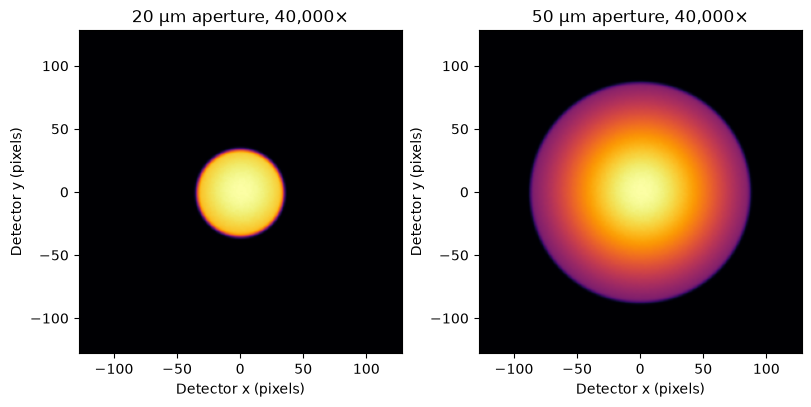

Parallel-illumination controls [CL1, CL3, mini]: [2.75415258 1.58915149 2.45      ]


In [5]:
from temgym_core.calibration.acquisition import render_ray_image
from temgym_core.calibration.projector_model import matrix5 as projector_matrix

parallel_controls = calibration.design_condenser_curve(
    parameters_by_voltage[0], image_magnifications=[0.25], mini_control=2.45,
)["controls"][0]
recorded = dict(np.load(reference / "settings.npz"))
baseline = np.flatnonzero(
    (recorded["voltage_index"] == 0)
    & (recorded["purpose"] == "projector")
    & (recorded["nominal_magnification"] == 40000)
)[0]
projector_controls = recorded["projector_controls"][baseline]
matrix = np.asarray(projector_matrix(jnp.array(truth["projector_parameters"]), projector_controls))
assert np.isclose(np.linalg.norm(matrix[:2, 0]), 40000)
assert np.linalg.norm(matrix[:2, 2:4]) < 1e-7

image_spec = dict(experiment, aperture_diameters_um=[20., 50.],
                  ray_sample_power=20, detector_samples_per_pixel=8)
image_settings = {
    "voltage_index": np.array([0]),
    "condenser_controls": np.array([parallel_controls]),
    "projector_controls": np.array([projector_controls]),
    "specimen_kick": np.zeros((1, 4)),
}
fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
for aperture_index, (ax, diameter) in enumerate(zip(axes, image_spec["aperture_diameters_um"])):
    image = render_ray_image(image_spec, image_settings, truth, row=0, aperture=aperture_index)
    ax.imshow(image, cmap="inferno", extent=[-128, 128, -128, 128])
    ax.set(title=f"{diameter:g} µm aperture, 40,000×",
           xlabel="Detector x (pixels)", ylabel="Detector y (pixels)")
plt.show()
print("Parallel-illumination controls [CL1, CL3, mini]:", parallel_controls)

**Current candidate:** 20/50 µm apertures, 40,000×/45,000×, mini fixed at 2.45, and CL1/CL3 on the parallel curve at source-image magnification 0.25. At 200 kV and 45,000× the geometric 4σ widths are approximately **77/178 pixels**, with **4.1 µrad RMS angular spread** and **15%/66% transmission**. The earlier 4/10 µm candidate gave 66/137 pixels.

The first crossover is near the middle of the CL1–CL3 gap. The complete-image checks cover both voltages, both magnifications and ±20 nm shifts in either axis. These are operating-condition checks, not a repeated inverse fit or a check of all calibration lens perturbations.

[20/50 µm study and complete detector images](../generated/tem_20_50_apertures/README.md).